# Branch D — economic resources and household pressure clustering

This notebook applies the agreed dimension-specific approach to the second dimension. It uses all 191 respondents whose validated final active branch is D.

Seven survey variables provide six equally weighted clustering components:

- household income band;
- working household-member proportion, derived from household workers and size;
- unemployed household-member proportion, derived from household unemployed and size;
- primary-earner responsibility;
- primary income source; and
- education funding source.

Household size is used as a denominator rather than added as another distance component, preventing the same household-count information from being counted repeatedly.

## Method

- Mixed-type, missing-aware Gower distance
- Candidate `k=2–5` comparison using K-medoids and spectral clustering
- Equal-weight consensus ensemble from 100 matched 80% subsamples per algorithm
- Final K-medoids partition of `1 − co-association`

Nominal categories are compared as same/different; they are not assigned arbitrary ranks. “Prefer not to say” is treated as unavailable household-income information, not the highest income category.

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, SpectralClustering
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

ROOT = Path.cwd()
VALUES_PATH = ROOT / "outputs/nysc_survey_cleaned_values.csv"
LABELS_PATH = ROOT / "outputs/nysc_survey_cleaned_labels.csv"
OUT = ROOT / "outputs/branch_d_economic_resources_clusters"
OUT.mkdir(parents=True, exist_ok=True)

SOURCE_VARIABLES = [
    "household_income", "household_size", "household_workers", "household_unemployed",
    "primary_earner_status", "primary_income_source", "edu_funding_source",
]
COMPONENTS = [
    "household_income_position", "household_worker_share", "household_unemployed_share",
    "primary_earner_responsibility", "primary_income_source", "education_funding_source",
]
RANDOM_STATE = 20260823
MIN_PROFILE_SIZE = 15
CANDIDATE_SUBSAMPLES = 50
CONSENSUS_SUBSAMPLES = 100
SUBSAMPLE_FRACTION = 0.80
ENSEMBLE_BOOTSTRAPS = 100

## 1. Rebuild and audit the strict Branch D cohort

In [2]:
values_all = pd.read_csv(VALUES_PATH)
labels_all = pd.read_csv(LABELS_PATH)
strict_mask = (
    values_all["branch"].eq("D")
    & values_all["branch_routing_source"].eq("translated_final_active_branch")
)
values = values_all.loc[strict_mask, [
    "respondent_id", "entry_branch", "branch", "branch_routing_source"
] + SOURCE_VARIABLES].copy()
labels = labels_all[["respondent_id"] + SOURCE_VARIABLES].copy()
cohort = values.merge(labels, on="respondent_id", suffixes=("__value", "__label"), validate="one_to_one")

inconsistent_counts = (
    cohort["household_workers__value"] + cohort["household_unemployed__value"]
    > cohort["household_size__value"]
)
validation = {
    "records": int(len(cohort)),
    "unique_ids": int(cohort["respondent_id"].nunique()),
    "wrong_branch": int(cohort["branch"].ne("D").sum()),
    "wrong_routing_source": int(cohort["branch_routing_source"].ne("translated_final_active_branch").sum()),
    "income_prefer_not_to_say": int(cohort["household_income__value"].eq(99).sum()),
    "workers_greater_than_household_size": int((cohort["household_workers__value"] > cohort["household_size__value"]).sum()),
    "unemployed_greater_than_household_size": int((cohort["household_unemployed__value"] > cohort["household_size__value"]).sum()),
    "workers_plus_unemployed_greater_than_size": int(inconsistent_counts.sum()),
}
assert validation["records"] == 191
assert validation["unique_ids"] == 191
assert validation["wrong_branch"] == 0
assert validation["wrong_routing_source"] == 0
assert validation["workers_greater_than_household_size"] == 0
assert validation["unemployed_greater_than_household_size"] == 0

display(pd.Series(validation, name="value").to_frame())
display(cohort.loc[inconsistent_counts, [
    "respondent_id", "household_size__value", "household_workers__value",
    "household_unemployed__value",
]])

,value
records,191
unique_ids,191
wrong_branch,0
wrong_routing_source,0
income_prefer_not_to_say,29
workers_greater_than_household_size,0
unemployed_greater_than_household_size,0
workers_plus_unemployed_greater_than_size,5


,respondent_id,household_size__value,household_workers__value,household_unemployed__value
0,nysc-7f7d7d2a-1592-4a24-8512-5986c27ddd28,3.0,2.0,2.0
24,nysc-3382bd6d-487e-4959-9964-4f8635ddbc99,2.0,2.0,1.0
74,nysc-83390495-2ae4-4bf8-a9e9-24b6e6fbb9cb,4.0,4.0,2.0
174,nysc-836e4ae3-c8a3-4aa4-9a9e-a1a3326a9598,5.0,3.0,3.0
190,nysc-25c345ec-5f45-4616-adb8-c96e31f3511c,4.0,3.0,4.0


## 2. Build six mixed-data components

Five inconsistent records remain in the cohort, but their worker and unemployment proportions are marked unavailable. Gower distance then uses their other observed economic components; one of these records also withheld income and therefore contributes three of six components. No count is silently corrected or imputed.

In [3]:
features = pd.DataFrame(index=cohort.index)

# Ordinal household income: 1=below 30k through 5=above 200k; 99=prefer not to say.
features["household_income_position"] = cohort["household_income__value"].where(
    cohort["household_income__value"].between(1, 5)
)

features["household_worker_share"] = (
    cohort["household_workers__value"] / cohort["household_size__value"]
).where(~inconsistent_counts)
features["household_unemployed_share"] = (
    cohort["household_unemployed__value"] / cohort["household_size__value"]
).where(~inconsistent_counts)

earner_map = {"no": 0.0, "shared": 0.5, "yes": 1.0}
features["primary_earner_responsibility"] = cohort["primary_earner_status__value"].map(earner_map)

# Nominal strings: equality only; numeric source codes are never treated as ordered.
features["primary_income_source"] = cohort["primary_income_source__label"].astype("string")
features["education_funding_source"] = cohort["edu_funding_source__label"].astype("string")

component_audit = pd.DataFrame({
    "component": COMPONENTS,
    "type": ["ordinal", "continuous proportion", "continuous proportion", "ordinal", "nominal", "nominal"],
    "source": [
        "household_income", "household_workers / household_size",
        "household_unemployed / household_size", "primary_earner_status",
        "primary_income_source", "edu_funding_source",
    ],
    "observed": [int(features[c].notna().sum()) for c in COMPONENTS],
    "missing": [int(features[c].isna().sum()) for c in COMPONENTS],
    "maximum_distance_weight": [1 / len(COMPONENTS)] * len(COMPONENTS),
})
assert features[COMPONENTS].notna().sum(axis=1).min() >= 3
display(component_audit)

# Respondent-level component export retains readable source responses.
component_export = cohort[["respondent_id"]].copy()
for component in COMPONENTS:
    component_export[component] = features[component]
component_export["count_consistency_flag"] = np.where(inconsistent_counts, "inconsistent_counts", "consistent")

,component,type,source,observed,missing,maximum_distance_weight
0,household_income_position,ordinal,household_income,162,29,0.166667
1,household_worker_share,continuous proportion,household_workers / household_size,186,5,0.166667
2,household_unemployed_share,continuous proportion,household_unemployed / household_size,186,5,0.166667
3,primary_earner_responsibility,ordinal,primary_earner_status,191,0,0.166667
4,primary_income_source,nominal,primary_income_source,191,0,0.166667
5,education_funding_source,nominal,edu_funding_source,191,0,0.166667


## 3. Calculate equal-weight, missing-aware mixed Gower distance

In [4]:
def mixed_gower(frame):
    n = len(frame)
    numerator = np.zeros((n, n), dtype=float)
    denominator = np.zeros((n, n), dtype=float)

    numeric_specs = {
        "household_income_position": 4.0,
        "household_worker_share": 1.0,
        "household_unemployed_share": 1.0,
        "primary_earner_responsibility": 1.0,
    }
    for column, theoretical_range in numeric_specs.items():
        values = pd.to_numeric(frame[column], errors="coerce").to_numpy(float)
        observed = np.isfinite(values)
        pair_observed = observed[:, None] & observed[None, :]
        difference = np.abs(values[:, None] - values[None, :]) / theoretical_range
        numerator += np.where(pair_observed, difference, 0.0)
        denominator += pair_observed

    for column in ["primary_income_source", "education_funding_source"]:
        values = frame[column].astype("object").to_numpy()
        observed = pd.notna(values)
        pair_observed = observed[:, None] & observed[None, :]
        difference = (values[:, None] != values[None, :]).astype(float)
        numerator += np.where(pair_observed, difference, 0.0)
        denominator += pair_observed

    distance = np.divide(numerator, denominator, out=np.zeros_like(numerator), where=denominator > 0)
    np.fill_diagonal(distance, 0.0)
    return distance, denominator


D, pair_component_coverage = mixed_gower(features)
assert np.allclose(D, D.T)
assert D.min() >= 0 and D.max() <= 1
assert pair_component_coverage.min() >= 3
sigma = float(np.median(D[D > 0]))

def affinity(distance):
    result = np.exp(-(distance ** 2) / (2 * sigma ** 2))
    np.fill_diagonal(result, 1.0)
    return result

print("Gower distance median:", round(float(np.median(D[D > 0])), 4))
print("Pairwise observed components: min", int(pair_component_coverage.min()),
      "median", int(np.median(pair_component_coverage)), "max", int(pair_component_coverage.max()))

Gower distance median: 0.28
Pairwise observed components: min 3 median 6 max 6


## 4. Select a common profile count for K-medoids and spectral clustering

The selected `k` minimizes the equal-weight rank of average source-algorithm Gower silhouette and average 80%-subsample stability. Cross-algorithm agreement is reported separately and cannot override the primary evidence.

In [5]:
def fit_kmedoids(D, k, n_init=200, max_iter=200, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    n = len(D)
    best = None
    for _ in range(n_init):
        medoids = np.sort(rng.choice(n, size=k, replace=False))
        for _ in range(max_iter):
            labels = np.argmin(D[:, medoids], axis=1)
            updated = medoids.copy()
            for cluster in range(k):
                members = np.flatnonzero(labels == cluster)
                if len(members) == 0:
                    nearest = D[:, medoids].min(axis=1)
                    available = np.setdiff1d(np.argsort(nearest)[::-1], updated)
                    updated[cluster] = available[0]
                else:
                    within = D[np.ix_(members, members)]
                    updated[cluster] = members[np.argmin(within.sum(axis=1))]
            if np.array_equal(updated, medoids):
                break
            medoids = updated
        labels = np.argmin(D[:, medoids], axis=1)
        loss = float(D[np.arange(n), medoids[labels]].sum())
        candidate = (loss, tuple(medoids.tolist()), medoids.copy(), labels.copy())
        if best is None or candidate[:2] < best[:2]:
            best = candidate
    return {"labels": best[3], "medoids": best[2], "loss": best[0]}


def medoids_from_labels(distance, labels):
    result = []
    for cluster in sorted(np.unique(labels)):
        members = np.flatnonzero(labels == cluster)
        within = distance[np.ix_(members, members)]
        result.append(members[np.argmin(within.sum(axis=1))])
    return np.asarray(result, dtype=int)


def subsample_stability(algorithm, k, reference_labels):
    rng = np.random.default_rng(RANDOM_STATE + 100 * k + (0 if algorithm == "kmedoids" else 10000))
    rows = []
    sample_size = int(np.floor(SUBSAMPLE_FRACTION * len(D)))
    for repetition in range(CANDIDATE_SUBSAMPLES):
        idx = np.sort(rng.choice(len(D), size=sample_size, replace=False))
        D_sub = D[np.ix_(idx, idx)]
        if algorithm == "kmedoids":
            result = fit_kmedoids(D_sub, k, n_init=50, random_state=RANDOM_STATE + 1000 * k + repetition)
            medoids = idx[result["medoids"]]
        else:
            labels_sub = SpectralClustering(
                n_clusters=k, affinity="precomputed", assign_labels="kmeans", n_init=30,
                random_state=RANDOM_STATE + 2000 * k + repetition,
            ).fit_predict(affinity(D_sub))
            medoids = idx[medoids_from_labels(D_sub, labels_sub)]
        predicted = np.argmin(D[:, medoids], axis=1)
        rows.append(adjusted_rand_score(reference_labels, predicted))
    return np.asarray(rows)


candidate_rows = []
full_source_solutions = {}
candidate_stability_rows = []

for k in range(2, 6):
    kmedoids = fit_kmedoids(D, k, n_init=400, random_state=RANDOM_STATE + k)
    spectral_labels = SpectralClustering(
        n_clusters=k, affinity="precomputed", assign_labels="kmeans", n_init=100,
        random_state=RANDOM_STATE + 100 + k,
    ).fit_predict(affinity(D))
    full_source_solutions[("kmedoids", k)] = kmedoids["labels"]
    full_source_solutions[("spectral", k)] = spectral_labels

    method_values = {}
    for algorithm, labels_k in [("kmedoids", kmedoids["labels"]), ("spectral", spectral_labels)]:
        stability = subsample_stability(algorithm, k, labels_k)
        method_values[algorithm] = {
            "silhouette": silhouette_score(D, labels_k, metric="precomputed"),
            "stability": float(stability.mean()),
            "stability_p10": float(np.quantile(stability, 0.10)),
            "minimum_size": int(pd.Series(labels_k).value_counts().min()),
        }
        candidate_stability_rows.extend({
            "algorithm": algorithm, "k": k, "repetition": i + 1, "ari": value
        } for i, value in enumerate(stability))

    candidate_rows.append({
        "k": k,
        "kmedoids_silhouette": method_values["kmedoids"]["silhouette"],
        "spectral_silhouette": method_values["spectral"]["silhouette"],
        "mean_source_silhouette": np.mean([method_values[a]["silhouette"] for a in ["kmedoids", "spectral"]]),
        "kmedoids_stability_mean": method_values["kmedoids"]["stability"],
        "spectral_stability_mean": method_values["spectral"]["stability"],
        "mean_source_stability": np.mean([method_values[a]["stability"] for a in ["kmedoids", "spectral"]]),
        "minimum_source_p10_stability": min(method_values[a]["stability_p10"] for a in ["kmedoids", "spectral"]),
        "source_algorithm_ari": adjusted_rand_score(kmedoids["labels"], spectral_labels),
        "minimum_cluster_size_across_sources": min(method_values[a]["minimum_size"] for a in ["kmedoids", "spectral"]),
    })

candidate_metrics = pd.DataFrame(candidate_rows)
candidate_stability = pd.DataFrame(candidate_stability_rows)
eligible = candidate_metrics.loc[
    candidate_metrics["minimum_cluster_size_across_sources"].ge(MIN_PROFILE_SIZE)
].copy()
if eligible.empty:
    raise RuntimeError("No k=2–5 candidate meets the minimum profile-size rule in both algorithms.")
eligible["rank_mean_silhouette"] = eligible["mean_source_silhouette"].rank(ascending=False, method="min")
eligible["rank_mean_stability"] = eligible["mean_source_stability"].rank(ascending=False, method="min")
eligible["primary_mean_rank"] = eligible[["rank_mean_silhouette", "rank_mean_stability"]].mean(axis=1)
best_rank = eligible["primary_mean_rank"].min()
selected_k = int(eligible.loc[eligible["primary_mean_rank"].eq(best_rank)].sort_values("k").iloc[0]["k"])
candidate_metrics = candidate_metrics.merge(eligible[["k", "primary_mean_rank"]], on="k", how="left")
candidate_metrics["selected"] = candidate_metrics["k"].eq(selected_k)

display(candidate_metrics.round(4))
print("Selected common k:", selected_k)

,k,kmedoids_silhouette,spectral_silhouette,mean_source_silhouette,kmedoids_stability_mean,spectral_stability_mean,mean_source_stability,minimum_source_p10_stability,source_algorithm_ari,minimum_cluster_size_across_sources,primary_mean_rank,selected
0,2,0.4302,0.3992,0.4147,0.9120,0.5971,0.7546,-0.0199,0.6628,35,1.0,True
1,3,0.4438,0.4342,0.4390,0.9611,0.8033,0.8822,0.7307,0.5802,8,NaN,False
2,4,0.2434,0.4450,0.3442,0.8272,0.7847,0.8060,0.4835,0.5069,5,NaN,False
3,5,0.2377,0.4329,0.3353,0.7121,0.7598,0.7359,0.4729,0.4900,1,NaN,False


Selected common k: 2


## 5. Construct the equal-weight consensus ensemble at the selected k

In [6]:
ensemble_rng = np.random.default_rng(RANDOM_STATE + 30000)
n = len(D)
sample_size = int(np.floor(SUBSAMPLE_FRACTION * n))
cover_matrices = []
same_matrices = []
base_rows = []

for repetition in range(CONSENSUS_SUBSAMPLES):
    idx = np.sort(ensemble_rng.choice(n, size=sample_size, replace=False))
    D_sub = D[np.ix_(idx, idx)]
    cover = np.zeros((n, n), dtype=np.uint8)
    cover[np.ix_(idx, idx)] = 1

    kmedoids_sub = fit_kmedoids(
        D_sub, selected_k, n_init=100,
        random_state=RANDOM_STATE + 40000 + repetition,
    )["labels"]
    spectral_sub = SpectralClustering(
        n_clusters=selected_k, affinity="precomputed", assign_labels="kmeans", n_init=30,
        random_state=RANDOM_STATE + 50000 + repetition,
    ).fit_predict(affinity(D_sub))

    for algorithm, labels_sub in [("kmedoids", kmedoids_sub), ("spectral", spectral_sub)]:
        same = np.zeros((n, n), dtype=np.uint8)
        same[np.ix_(idx, idx)] = (labels_sub[:, None] == labels_sub[None, :]).astype(np.uint8)
        cover_matrices.append(cover.copy())
        same_matrices.append(same)
        base_rows.append({
            "partition_id": len(base_rows) + 1,
            "algorithm": algorithm,
            "repetition": repetition + 1,
            "silhouette_in_subsample": silhouette_score(D_sub, labels_sub, metric="precomputed"),
            "minimum_cluster_size": int(pd.Series(labels_sub).value_counts().min()),
        })

cover_stack = np.stack(cover_matrices)
same_stack = np.stack(same_matrices)
coverage = cover_stack.sum(axis=0)
together = same_stack.sum(axis=0)
consensus = together / coverage
np.fill_diagonal(consensus, 1.0)
consensus_distance = 1 - consensus
np.fill_diagonal(consensus_distance, 0.0)
base_partition_diagnostics = pd.DataFrame(base_rows)

final_fit = fit_kmedoids(
    consensus_distance, selected_k, n_init=500,
    random_state=RANDOM_STATE + 60000,
)
raw_labels = final_fit["labels"]

print("Base partitions:", len(base_partition_diagnostics))
print("Pair coverage: min", int(coverage.min()), "median", int(np.median(coverage)), "max", int(coverage.max()))
display(base_partition_diagnostics.groupby("algorithm").agg(
    partitions=("partition_id", "size"),
    mean_silhouette=("silhouette_in_subsample", "mean"),
    minimum_cluster_size=("minimum_cluster_size", "min"),
).round(3))

Base partitions: 200
Pair coverage: min 88 median 126 max 178


,partitions,mean_silhouette,minimum_cluster_size
algorithm,,,
kmedoids,100,0.431,30
spectral,100,0.434,5


## 6. Profile and label the economic-resource clusters

In [7]:
display_scores = pd.DataFrame(index=cohort.index)
display_scores["income_position"] = 100 * (features["household_income_position"] - 1) / 4
display_scores["working_member_share"] = 100 * features["household_worker_share"]
display_scores["freedom_from_unemployment_burden"] = 100 * (1 - features["household_unemployed_share"])
display_scores["freedom_from_primary_earner_burden"] = 100 * (1 - features["primary_earner_responsibility"])
display_scores["raw_cluster"] = raw_labels

raw_orientation = display_scores.groupby("raw_cluster").mean().mean(axis=1)
raw_order = raw_orientation.sort_values().index.tolist()
raw_to_profile = {int(old): int(i + 1) for i, old in enumerate(raw_order)}
profile_id = np.array([raw_to_profile[int(label)] for label in raw_labels])
display_scores["economic_profile_id"] = profile_id
profile_numeric_means = display_scores.groupby("economic_profile_id").mean(numeric_only=True).drop(columns="raw_cluster", errors="ignore")

def profile_name(pid, row):
    if pid == profile_numeric_means.index.min():
        description = "relatively lower household economic position"
    elif pid == profile_numeric_means.index.max():
        description = "relatively higher household economic position"
    else:
        description = "intermediate household economic position"
    return f"Economic profile {pid}: {description}"

profile_names = {
    int(pid): profile_name(int(pid), profile_numeric_means.loc[pid])
    for pid in profile_numeric_means.index
}

gower_individual_silhouette = silhouette_samples(D, profile_id, metric="precomputed")
consensus_individual_silhouette = silhouette_samples(consensus_distance, profile_id, metric="precomputed")

assignments = cohort[["respondent_id", "entry_branch", "branch", "branch_routing_source"]].copy()
for variable in SOURCE_VARIABLES:
    assignments[f"{variable}__value"] = cohort[f"{variable}__value"]
    assignments[f"{variable}__response"] = cohort[f"{variable}__label"]
assignments = assignments.merge(component_export, on="respondent_id", validate="one_to_one")
assignments["economic_profile_id"] = profile_id
assignments["economic_profile_label"] = assignments["economic_profile_id"].map(profile_names)
assignments["gower_individual_silhouette"] = gower_individual_silhouette
assignments["consensus_individual_silhouette"] = consensus_individual_silhouette

profile_sizes = (
    assignments.groupby(["economic_profile_id", "economic_profile_label"], as_index=False)
    .agg(records=("respondent_id", "size"),
         low_gower_confidence_records=("gower_individual_silhouette", lambda x: int((x < 0.10).sum())),
         mean_gower_silhouette=("gower_individual_silhouette", "mean"),
         mean_consensus_silhouette=("consensus_individual_silhouette", "mean"))
)
profile_sizes["percent"] = 100 * profile_sizes["records"] / len(assignments)

nominal_rows = []
for variable in ["primary_income_source", "edu_funding_source", "primary_earner_status", "household_income"]:
    response_col = f"{variable}__response"
    temp = assignments.groupby(["economic_profile_id", response_col], dropna=False).size().rename("records").reset_index()
    temp["within_profile_percent"] = 100 * temp["records"] / temp.groupby("economic_profile_id")["records"].transform("sum")
    temp = temp.rename(columns={response_col: "response"})
    temp.insert(1, "variable", variable)
    nominal_rows.append(temp)
profile_response_distributions = pd.concat(nominal_rows, ignore_index=True)

profile_modes = (
    profile_response_distributions.sort_values(
        ["economic_profile_id", "variable", "within_profile_percent"],
        ascending=[True, True, False],
    ).groupby(["economic_profile_id", "variable"], as_index=False).first()
)

display(profile_sizes.round(3))
display(profile_numeric_means.round(2))
display(profile_modes.round(2))

,economic_profile_id,economic_profile_label,records,low_gower_confidence_records,mean_gower_silhouette,mean_consensus_silhouette,percent
0,1,Economic profile 1: relatively lower household...,44,11,0.194,0.782,23.037
1,2,Economic profile 2: relatively higher househol...,147,3,0.509,0.918,76.963


,income_position,working_member_share,freedom_from_unemployment_burden,freedom_from_primary_earner_burden
economic_profile_id,,,,
1,50.00,37.22,72.58,85.23
2,76.02,47.79,76.05,93.88


,economic_profile_id,variable,response,records,within_profile_percent
0,1,edu_funding_source,Government-funded or free of charge,33,75.00
1,1,household_income,"LKR 120,000 – 200,000",10,22.73
2,1,primary_earner_status,No — someone else is the main provider,36,81.82
3,1,primary_income_source,My parents or family,30,68.18
4,2,edu_funding_source,Paid for by my family,139,94.56
5,2,household_income,"Above LKR 200,000",58,39.46
6,2,primary_earner_status,No — someone else is the main provider,134,91.16
7,2,primary_income_source,My parents or family,119,80.95


## 7. Validate consensus stability, source agreement and ambiguity

In [8]:
# Respondent consensus confidence.
confidence_rows = []
for i in range(n):
    own = profile_id[i]
    own_members = np.flatnonzero(profile_id == own)
    own_members = own_members[own_members != i]
    within = float(consensus[i, own_members].mean()) if len(own_members) else 1.0
    strongest_other = max(
        float(consensus[i, np.flatnonzero(profile_id == other)].mean())
        for other in sorted(set(profile_id) - {own})
    )
    confidence_rows.append({
        "respondent_id": cohort.iloc[i]["respondent_id"],
        "economic_profile_id": int(own),
        "within_profile_consensus": within,
        "strongest_other_profile_consensus": strongest_other,
        "consensus_margin": within - strongest_other,
        "ambiguous_consensus_membership": (within < 0.70) or ((within - strongest_other) < 0.20),
    })
respondent_confidence = pd.DataFrame(confidence_rows)
assignments = assignments.merge(
    respondent_confidence.drop(columns="economic_profile_id"),
    on="respondent_id", validate="one_to_one",
)

# Resample the 200 base partitions.
bootstrap_rng = np.random.default_rng(RANDOM_STATE + 70000)
ensemble_stability_rows = []
for repetition in range(ENSEMBLE_BOOTSTRAPS):
    selected = bootstrap_rng.choice(len(cover_stack), size=len(cover_stack), replace=True)
    boot_cover = cover_stack[selected].sum(axis=0)
    boot_same = same_stack[selected].sum(axis=0)
    boot_consensus = np.divide(boot_same, boot_cover, out=np.zeros_like(boot_same, dtype=float), where=boot_cover > 0)
    np.fill_diagonal(boot_consensus, 1.0)
    boot_distance = 1 - boot_consensus
    np.fill_diagonal(boot_distance, 0.0)
    boot_labels = fit_kmedoids(
        boot_distance, selected_k, n_init=80,
        random_state=RANDOM_STATE + 80000 + repetition,
    )["labels"]
    ensemble_stability_rows.append({
        "repetition": repetition + 1,
        "ari_vs_full_consensus": adjusted_rand_score(profile_id, boot_labels),
    })
ensemble_stability = pd.DataFrame(ensemble_stability_rows)

full_kmedoids = full_source_solutions[("kmedoids", selected_k)]
full_spectral = full_source_solutions[("spectral", selected_k)]
consensus_hac_average = AgglomerativeClustering(
    n_clusters=selected_k, metric="precomputed", linkage="average"
).fit_predict(consensus_distance)
consensus_hac_complete = AgglomerativeClustering(
    n_clusters=selected_k, metric="precomputed", linkage="complete"
).fit_predict(consensus_distance)

upper = consensus[np.triu_indices(n, 1)]
pac_10_90 = float(np.mean((upper > 0.10) & (upper < 0.90)))
metrics = {
    "gower_silhouette": float(silhouette_score(D, profile_id, metric="precomputed")),
    "consensus_distance_silhouette": float(silhouette_score(consensus_distance, profile_id, metric="precomputed")),
    "ensemble_bootstrap_ari_mean": float(ensemble_stability["ari_vs_full_consensus"].mean()),
    "ensemble_bootstrap_ari_p10": float(ensemble_stability["ari_vs_full_consensus"].quantile(0.10)),
    "ari_vs_full_kmedoids": float(adjusted_rand_score(profile_id, full_kmedoids)),
    "ari_vs_full_spectral": float(adjusted_rand_score(profile_id, full_spectral)),
    "ari_consensus_kmedoids_vs_hac_average": float(adjusted_rand_score(profile_id, consensus_hac_average)),
    "ari_consensus_kmedoids_vs_hac_complete": float(adjusted_rand_score(profile_id, consensus_hac_complete)),
    "minimum_profile_size": int(pd.Series(profile_id).value_counts().min()),
    "low_gower_confidence_percent": 100 * float(np.mean(gower_individual_silhouette < 0.10)),
    "ambiguous_consensus_percent": 100 * float(assignments["ambiguous_consensus_membership"].mean()),
    "pac_10_90": pac_10_90,
}

quality_checks = pd.DataFrame([
    {"check": "original Gower silhouette >= 0.25", "value": metrics["gower_silhouette"], "passed": metrics["gower_silhouette"] >= 0.25},
    {"check": "ensemble bootstrap mean ARI >= 0.80", "value": metrics["ensemble_bootstrap_ari_mean"], "passed": metrics["ensemble_bootstrap_ari_mean"] >= 0.80},
    {"check": f"minimum profile size >= {MIN_PROFILE_SIZE}", "value": metrics["minimum_profile_size"], "passed": metrics["minimum_profile_size"] >= MIN_PROFILE_SIZE},
    {"check": "ARI with full K-medoids >= 0.60", "value": metrics["ari_vs_full_kmedoids"], "passed": metrics["ari_vs_full_kmedoids"] >= 0.60},
    {"check": "ARI with full spectral >= 0.60", "value": metrics["ari_vs_full_spectral"], "passed": metrics["ari_vs_full_spectral"] >= 0.60},
    {"check": "PAC (0.10, 0.90) <= 0.20", "value": metrics["pac_10_90"], "passed": metrics["pac_10_90"] <= 0.20},
    {"check": "ambiguous consensus respondents <= 20%", "value": metrics["ambiguous_consensus_percent"], "passed": metrics["ambiguous_consensus_percent"] <= 20},
    {"check": "low-confidence respondents in original Gower space <= 20%", "value": metrics["low_gower_confidence_percent"], "passed": metrics["low_gower_confidence_percent"] <= 20},
])
primary_pass = bool(quality_checks.iloc[:5]["passed"].all())
if primary_pass and quality_checks.iloc[5:]["passed"].all():
    status = "Stable, cross-method-supported economic-resource segmentation"
elif primary_pass:
    status = "Passes primary stability rules but retains ambiguity cautions"
else:
    status = "No sufficiently robust economic-resource segmentation found"

display(pd.Series(metrics, name="value").to_frame().round(3))
display(quality_checks.round(3))
print("Decision:", status)

,value
gower_silhouette,0.436
consensus_distance_silhouette,0.887
ensemble_bootstrap_ari_mean,0.986
ensemble_bootstrap_ari_p10,0.955
ari_vs_full_kmedoids,0.849
ari_vs_full_spectral,0.796
ari_consensus_kmedoids_vs_hac_average,0.869
ari_consensus_kmedoids_vs_hac_complete,0.869
minimum_profile_size,44.000
low_gower_confidence_percent,7.330


,check,value,passed
0,original Gower silhouette >= 0.25,0.436,True
1,ensemble bootstrap mean ARI >= 0.80,0.986,True
2,minimum profile size >= 15,44.000,True
3,ARI with full K-medoids >= 0.60,0.849,True
4,ARI with full spectral >= 0.60,0.796,True
5,"PAC (0.10, 0.90) <= 0.20",0.422,False
6,ambiguous consensus respondents <= 20%,6.283,True
7,low-confidence respondents in original Gower s...,7.330,True


Decision: Passes primary stability rules but retains ambiguity cautions


## 8. Visual summaries

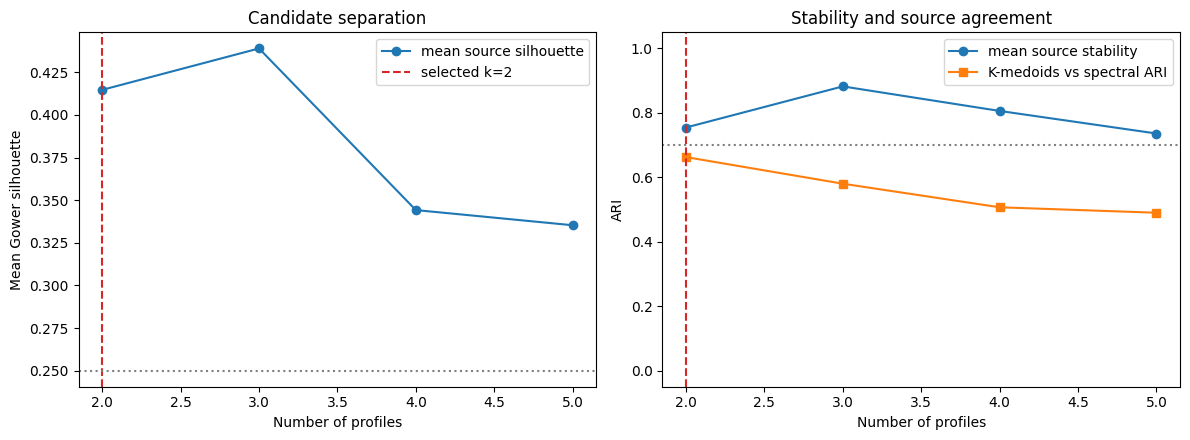

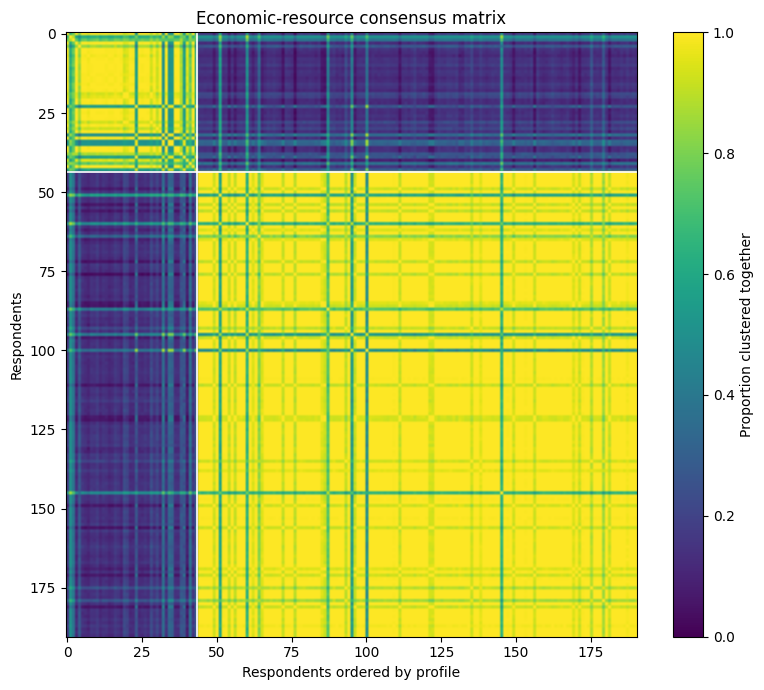

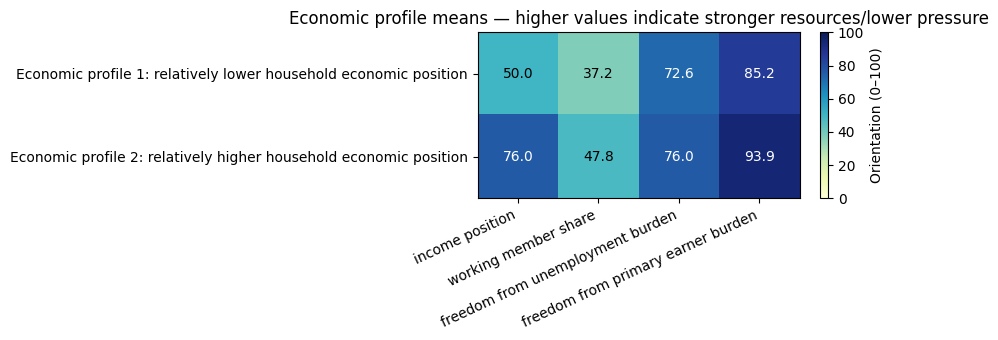

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(candidate_metrics["k"], candidate_metrics["mean_source_silhouette"], marker="o", label="mean source silhouette")
axes[0].axvline(selected_k, color="tab:red", linestyle="--", label=f"selected k={selected_k}")
axes[0].axhline(0.25, color="grey", linestyle=":")
axes[0].set(title="Candidate separation", xlabel="Number of profiles", ylabel="Mean Gower silhouette")
axes[0].legend()
axes[1].plot(candidate_metrics["k"], candidate_metrics["mean_source_stability"], marker="o", label="mean source stability")
axes[1].plot(candidate_metrics["k"], candidate_metrics["source_algorithm_ari"], marker="s", label="K-medoids vs spectral ARI")
axes[1].axvline(selected_k, color="tab:red", linestyle="--")
axes[1].axhline(0.70, color="grey", linestyle=":")
axes[1].set(title="Stability and source agreement", xlabel="Number of profiles", ylabel="ARI", ylim=(-0.05, 1.05))
axes[1].legend()
fig.tight_layout()
fig.savefig(OUT / "economic_candidate_diagnostics.png", dpi=180, bbox_inches="tight")
plt.show()

order = np.argsort(profile_id, kind="stable")
fig, ax = plt.subplots(figsize=(8, 7))
heat = ax.imshow(consensus[np.ix_(order, order)], cmap="viridis", vmin=0, vmax=1, aspect="auto")
boundaries = np.cumsum(pd.Series(profile_id[order]).value_counts(sort=False).sort_index().to_numpy())[:-1]
for boundary in boundaries:
    ax.axhline(boundary - 0.5, color="white", linewidth=1.2)
    ax.axvline(boundary - 0.5, color="white", linewidth=1.2)
ax.set(title="Economic-resource consensus matrix", xlabel="Respondents ordered by profile", ylabel="Respondents")
fig.colorbar(heat, ax=ax, label="Proportion clustered together")
fig.tight_layout()
fig.savefig(OUT / "economic_consensus_matrix_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, max(3.5, selected_k * 0.75)))
heat = ax.imshow(profile_numeric_means.to_numpy(), cmap="YlGnBu", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(profile_numeric_means.columns)), [c.replace("_", " ") for c in profile_numeric_means.columns], rotation=25, ha="right")
ax.set_yticks(range(selected_k), [profile_names[int(i)] for i in profile_numeric_means.index])
for i in range(selected_k):
    for j in range(len(profile_numeric_means.columns)):
        value = profile_numeric_means.iloc[i, j]
        ax.text(j, i, f"{value:.1f}", ha="center", va="center", color="white" if value > 65 else "black")
ax.set_title("Economic profile means — higher values indicate stronger resources/lower pressure")
fig.colorbar(heat, ax=ax, label="Orientation (0–100)")
fig.tight_layout()
fig.savefig(OUT / "economic_profile_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

## 9. Save reproducible outputs

In [10]:
component_audit.to_csv(OUT / "economic_component_audit.csv", index=False)
component_export.to_csv(OUT / "economic_components.csv", index=False)
candidate_metrics.to_csv(OUT / "economic_candidate_metrics.csv", index=False)
candidate_stability.to_csv(OUT / "economic_candidate_subsample_stability.csv", index=False)
base_partition_diagnostics.to_csv(OUT / "economic_consensus_base_partitions.csv", index=False)
assignments.to_csv(OUT / "economic_consensus_assignments.csv", index=False)
profile_sizes.to_csv(OUT / "economic_profile_sizes.csv", index=False)
profile_numeric_means.to_csv(OUT / "economic_profile_numeric_means.csv")
profile_response_distributions.to_csv(OUT / "economic_profile_response_distributions.csv", index=False)
profile_modes.to_csv(OUT / "economic_profile_modes.csv", index=False)
respondent_confidence.to_csv(OUT / "economic_respondent_consensus_confidence.csv", index=False)
ensemble_stability.to_csv(OUT / "economic_consensus_ensemble_stability.csv", index=False)
quality_checks.to_csv(OUT / "economic_quality_checks.csv", index=False)

consensus_export = pd.DataFrame(consensus, columns=cohort["respondent_id"])
consensus_export.insert(0, "respondent_id", cohort["respondent_id"].to_numpy())
consensus_export.to_csv(OUT / "economic_consensus_matrix.csv", index=False)

summary = {
    "cohort": {
        "records": int(len(cohort)), "branch": "D",
        "routing_source": "translated_final_active_branch",
    },
    "dimension": "economic resources and household pressure",
    "source_variables": SOURCE_VARIABLES,
    "clustering_components": COMPONENTS,
    "data_quality": validation,
    "method": {
        "distance": "equal-weight mixed, missing-aware Gower",
        "candidate_k": [2, 3, 4, 5],
        "selected_k": selected_k,
        "ensemble": "equal-weight K-medoids plus spectral consensus",
        "base_partitions": 2 * CONSENSUS_SUBSAMPLES,
        "final_method": "K-medoids on one minus co-association",
    },
    "profiles": {
        "sizes": {str(int(r.economic_profile_id)): int(r.records) for r in profile_sizes.itertuples()},
        "names": {str(k): v for k, v in profile_names.items()},
    },
    "metrics": metrics,
    "decision": {
        "primary_checks_passed": primary_pass,
        "checks_passed": int(quality_checks["passed"].sum()),
        "checks_total": int(len(quality_checks)),
        "status": status,
    },
    "limitations": [
        "29 respondents declined household income; missing-aware Gower excludes that component pairwise.",
        "Five records have workers plus unemployed greater than household size; both derived shares are unavailable for those records.",
        "Nominal income and education funding sources use exact category matching and no invented ordering.",
    ],
}

with open(OUT / "economic_clustering_summary.json", "w", encoding="utf-8") as handle:
    json.dump(summary, handle, indent=2)

print(json.dumps(summary, indent=2))
print("\nSaved files:")
for path in sorted(OUT.iterdir()):
    print(" -", path.name)

{
  "cohort": {
    "records": 191,
    "branch": "D",
    "routing_source": "translated_final_active_branch"
  },
  "dimension": "economic resources and household pressure",
  "source_variables": [
    "household_income",
    "household_size",
    "household_workers",
    "household_unemployed",
    "primary_earner_status",
    "primary_income_source",
    "edu_funding_source"
  ],
  "clustering_components": [
    "household_income_position",
    "household_worker_share",
    "household_unemployed_share",
    "primary_earner_responsibility",
    "primary_income_source",
    "education_funding_source"
  ],
  "data_quality": {
    "records": 191,
    "unique_ids": 191,
    "wrong_branch": 0,
    "wrong_routing_source": 0,
    "income_prefer_not_to_say": 29,
    "workers_greater_than_household_size": 0,
    "unemployed_greater_than_household_size": 0,
    "workers_plus_unemployed_greater_than_size": 5
  },
  "method": {
    "distance": "equal-weight mixed, missing-aware Gower",
    "cand

## Interpretation guardrails

- These profiles describe economic resources and household pressure only.
- They do not measure motivation, educational merit, programme suitability or respondent worth.
- Nominal funding/source differences can separate profiles even when numeric resource levels are similar; always interpret the response distributions alongside the numeric heatmap.
- Missing-aware Gower retains respondents without inventing income or household counts, but their distances use fewer components.
- A stable consensus does not establish causal economic classes.